<a href="https://colab.research.google.com/github/Ansarss/Ai_learning_experiments/blob/main/Medical_Text_Transformer_Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Medical Text Classification: Traditional ML vs. Transformers

**Reproducible Google Colab experiment | Academic use only**

**Research task:** Predict the medical specialty associated with a transcription. This is **not** a diagnosis prediction or a validated clinical decision-support system. The MTSamples corpus is made of sample transcriptions rather than a representative prospective patient cohort.

**Methods:** three TF-IDF + classical models, ClinicalBERT, PubMedBERT; training-only cross-validation; validation-based hyperparameter choice; final held-out test; macro-F1, recall/precision/ROC-AUC, error analysis, internal stress tests, interpretability, exact McNemar, bootstrap CIs, exploratory paired t-tests, and MLflow tracking.

**Instructions:** In Colab select **Runtime → Change runtime type → T4 GPU**. Run cells in order. Results and plots appear under `/content/medical_model_outputs` and can be downloaded as a ZIP. Kaggle access may require authentication. Do not upload identifiable clinical documents.

In [1]:
%pip -q install 'transformers>=4.48,<5' 'datasets>=3,<5' 'accelerate>=1,<2' kagglehub mlflow shap lime psutil statsmodels scikit-learn scipy pandas matplotlib seaborn joblib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 1. Reproducibility, environment, and audit boundaries

Before running, record Colab's GPU type, package versions, the model checkpoint revision (if your study requires strict version pinning), date, and random seed. The regex redactions below are only a screening aid, **not** verified HIPAA de-identification. Keep outputs from sensitive text private.

In [2]:
import os, re, gc, json, time, random, hashlib, itertools, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import joblib, psutil, torch, scipy, sklearn
from scipy.stats import binomtest, ttest_rel
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc, classification_report)
from statsmodels.stats.multitest import multipletests
import mlflow

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
OUT = Path('/content/medical_model_outputs') if Path('/content').exists() else Path('./medical_model_outputs')
OUT.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(f"sqlite:///{(OUT / 'mlflow.db').resolve()}")
mlflow.set_experiment('MTSamples Medical Specialty Comparison')
print({'python':platform.python_version(), 'sklearn':sklearn.__version__,
       'torch':torch.__version__, 'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU',
       'seed':SEED, 'output':str(OUT)})

2026/11/21 23:39:37 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/21 23:39:38 INFO mlflow.store.db.utils: Updating database tables
2026/11/21 23:39:40 INFO mlflow.tracking.fluent: Experiment with name 'MTSamples Medical Specialty Comparison' does not exist. Creating a new experiment.


{'python': '3.13.16', 'sklearn': '1.6.1', 'torch': '2.14.1+cu130', 'gpu': 'NVIDIA A100-SXM4-80GB', 'seed': 42, 'output': '/content/medical_model_outputs'}


## 2. Load the named Kaggle dataset

Data provenance: [Kaggle: Medical Transcriptions](https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions). The CSV normally contains `transcription` and `medical_specialty`. Only the transcription is used as input, to avoid label leakage from `keywords`, `description`, or `sample_name`.

In [3]:
import kagglehub
try:
    folder = Path(kagglehub.dataset_download('tboyle10/medicaltranscriptions'))
    csv_files = list(folder.rglob('mtsamples.csv'))
    if not csv_files:
        csv_files = list(folder.rglob('*.csv'))
    csv_path = csv_files[0]
except Exception as exc:
    print('Kaggle download unavailable. Upload the mtsamples.csv file manually.')
    print('Reason:', str(exc)[:300])
    from google.colab import files
    uploaded = files.upload()
    csv_path = Path(next(iter(uploaded.keys())))
raw = pd.read_csv(csv_path)
assert {'transcription', 'medical_specialty'}.issubset(raw.columns), raw.columns.tolist()
print('Raw shape:', raw.shape, 'Columns:', raw.columns.tolist())
print('Missing transcription:', int(raw.transcription.isna().sum()))
print('Missing medical_specialty:', int(raw.medical_specialty.isna().sum()))
print('Top specialty label counts (before cleaning):')
print(raw.medical_specialty.astype(str).str.strip().value_counts().head(12))

100%|██████████| 4.85M/4.85M [00:00<00:00, 6.84MB/s]

Extracting files...


Raw shape: (4999, 6) Columns: ['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']
Missing transcription: 33
Missing medical_specialty: 0
Top specialty label counts (before cleaning):
medical_specialty
Surgery                          1103
Consult - History and Phy.        516
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  230
Neurology                         223
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
Name: count, dtype: int64


## 3. Sanitize, check ambiguity, and define the single-label study cohort

**Important:** MTSamples can contain repeated or cross-listed notes. An identical transcription assigned to two different specialties is ambiguous for single-label evaluation. We exclude those conflicting cases, deduplicate identical same-label notes, and document the number removed. This is an explicit study-design choice, not proof that one label is clinically correct.

Do not automatically remove negations such as `no`, `not`, or `without`; they can reverse clinical meaning. Exact note copies are blocked across splits; **near duplicates still require a manual audit**.

Counts after selecting predefined specialties, before deduplication:
label
Cardiovascular / Pulmonary    368
Orthopedic                    347
Neurology                     223
Gastroenterology              221
Urology                       155
Name: count, dtype: int64
Counts after removing conflicting and same-label duplicate transcriptions:
label
Cardiovascular / Pulmonary    363
Orthopedic                    312
Gastroenterology              213
Neurology                     185
Urology                       151
Name: count, dtype: int64
Ambiguous duplicated rows excluded: 90
Same-label duplicate rows dropped: 0
Final cohort: (1224, 6) 
 label
Cardiovascular / Pulmonary    363
Orthopedic                    312
Gastroenterology              213
Neurology                     185
Urology                       151
Name: count, dtype: int64


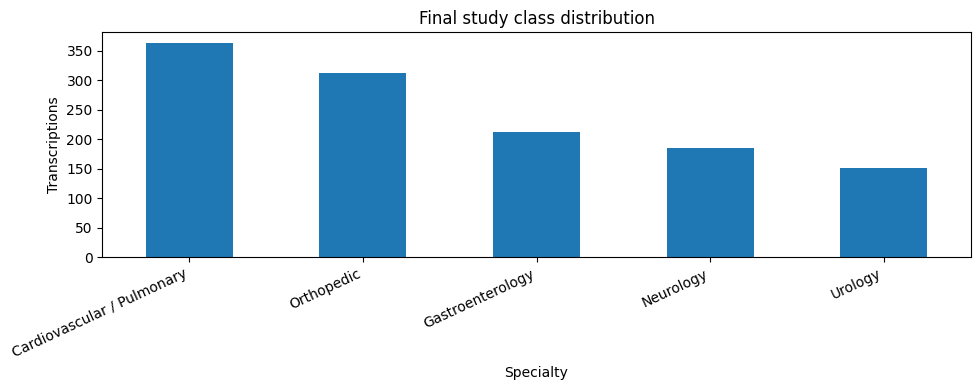

In [4]:
def normalize_note(s):
    s = re.sub(r'\s+', ' ', str(s)).strip()
    # Indicative scrub, not validated de-identification for real clinical PHI.
    s = re.sub(r'[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}', '[EMAIL]', s)
    s = re.sub(r'(?<!\d)(?:\+1[-. ]?)?\(?\d{3}\)?[-. ]?\d{3}[-. ]?\d{4}(?!\d)', '[PHONE]', s)
    return s

df = raw[['transcription', 'medical_specialty']].dropna().copy()
df['text'] = df['transcription'].map(normalize_note)
df['label'] = df['medical_specialty'].astype(str).str.strip()
df = df[(df.text.str.len() >= 80) & (df.label.str.len() > 0)].copy()

# Predefine specific clinical specialties BEFORE removing conflicting duplicates.
# The umbrella categories Surgery and Consult - History and Phy. are not included.
TARGET_LABELS = ['Cardiovascular / Pulmonary', 'Orthopedic',
                 'Gastroenterology', 'Neurology', 'Urology']
TOP_K = len(TARGET_LABELS)
MIN_PER_CLASS = 30
missing_labels = set(TARGET_LABELS) - set(df['label'].unique())
if missing_labels:
    raise ValueError(f'Selected specialties missing from dataset: {missing_labels}')
df = df[df['label'].isin(TARGET_LABELS)].copy()
print('Counts after selecting predefined specialties, before deduplication:')
print(df['label'].value_counts())

df['signature'] = df['text'].str.casefold().str.replace(r'\s+', ' ', regex=True)
ambiguous = df.groupby('signature')['label'].nunique()
ambiguous_signatures = set(ambiguous[ambiguous > 1].index)
ambiguous_n = int(df['signature'].isin(ambiguous_signatures).sum())
df = df[~df['signature'].isin(ambiguous_signatures)].copy()
remaining_same_label_dups = int(df.duplicated('signature').sum())
df = df.drop_duplicates(subset='signature').copy()

counts = df['label'].value_counts()
print('Counts after removing conflicting and same-label duplicate transcriptions:')
print(counts)
keep_labels = [label for label in TARGET_LABELS if counts.get(label, 0) >= MIN_PER_CLASS]
df = df[df['label'].isin(keep_labels)].copy().reset_index(drop=True)
if df['label'].nunique() < 3:
    raise ValueError('Fewer than three classes remain after cleaning; inspect printed counts. '
                     'Do not silently lower thresholds or assign arbitrary labels.')
if df['label'].value_counts().min() < 10:
    raise ValueError('Too few records for a reliable stratified split.')
enc = LabelEncoder(); df['y'] = enc.fit_transform(df.label)
class_names = list(enc.classes_); n_classes = len(class_names)
with open(OUT/'cohort_audit.json', 'w') as f:
    json.dump({'raw_rows':int(len(raw)), 'rows_after_cleaning_and_class_filter':int(len(df)),
               'conflicting_duplicate_rows_excluded':ambiguous_n,
               'same_label_duplicate_rows_removed':remaining_same_label_dups,
               'classes':df.label.value_counts().to_dict(), 'selected_specialties':TARGET_LABELS,
               'class_selection_strategy':'predefined five specialties, filter then deduplicate',
               'top_k':TOP_K, 'min_per_class':MIN_PER_CLASS}, f, indent=2)
print('Ambiguous duplicated rows excluded:', ambiguous_n)
print('Same-label duplicate rows dropped:', remaining_same_label_dups)
print('Final cohort:', df.shape, '\n', df.label.value_counts())
fig, ax=plt.subplots(figsize=(10,4)); df.label.value_counts().plot(kind='bar',ax=ax)
ax.set(title='Final study class distribution', ylabel='Transcriptions', xlabel='Specialty'); plt.xticks(rotation=25,ha='right')
fig.tight_layout(); fig.savefig(OUT/'class_distribution.png',dpi=180); plt.show()


## 4. Locked 70% / 15% / 15% train–validation–test split

The test partition is held out until model choices are determined on training CV + validation only. Since exact duplicates are removed beforehand, an identical note cannot cross split boundaries. If patient or source IDs become available, use patient/source-grouped splits instead.

In [5]:
train_idx, other_idx = train_test_split(df.index, test_size=0.30, random_state=SEED, stratify=df.y)
val_idx, test_idx = train_test_split(other_idx, test_size=0.50, random_state=SEED,
                                     stratify=df.loc[other_idx,'y'])
train=df.loc[train_idx].reset_index(drop=True)
val=df.loc[val_idx].reset_index(drop=True)
test=df.loc[test_idx].reset_index(drop=True)
assert set(train.signature).isdisjoint(set(val.signature))
assert set(train.signature).isdisjoint(set(test.signature))
assert set(val.signature).isdisjoint(set(test.signature))
print('Train / validation / test:',len(train),len(val),len(test))
print(pd.concat({'train':train.label.value_counts(), 'validation':val.label.value_counts(),
                 'test':test.label.value_counts()},axis=1).fillna(0).astype(int))
for name,subset in [('train',train),('validation',val),('test',test)]:
    pd.DataFrame({'record_id':subset.signature.apply(lambda s:hashlib.sha256(s.encode()).hexdigest()[:14]),
                  'label':subset.label}).to_csv(OUT/f'{name}_split_manifest.csv', index=False)

Train / validation / test: 856 184 184
                            train  validation  test
label                                              
Cardiovascular / Pulmonary    254          54    55
Orthopedic                    218          47    47
Gastroenterology              149          32    32
Neurology                     129          28    28
Urology                       106          23    22


## 5. Definitions: primary and secondary metrics

**Primary endpoint:** macro F1, which gives each specialty equal weight. **Secondary:** accuracy, macro precision/recall, macro one-vs-rest ROC-AUC, confusion matrices, per-class sensitivity, prediction latency, and model size. Report all scores on the same held-out test set. ROC-AUC requires class probabilities; SVM probabilities are estimated via internal calibration on training folds.

In [6]:
def evaluate_arrays(y_true, probs):
    probs=np.asarray(probs)
    pred=np.argmax(probs,axis=1)
    prec,rec,f1,_=precision_recall_fscore_support(y_true,pred,labels=np.arange(n_classes),
                                                    average='macro',zero_division=0)
    result={'accuracy':float(accuracy_score(y_true,pred)), 'precision_macro':float(prec),
            'recall_macro':float(rec), 'f1_macro':float(f1)}
    try:
        result['roc_auc_ovr_macro']=float(roc_auc_score(y_true,probs,labels=np.arange(n_classes),
                                                          multi_class='ovr',average='macro'))
    except ValueError:
        result['roc_auc_ovr_macro']=float('nan')
    return result

def log_metrics_clean(metrics,prefix):
    mlflow.log_metrics({f'{prefix}_{k}':v for k,v in metrics.items() if np.isfinite(v)})

val_predictions={}; fitted={}; model_metadata={}; val_records={}

## 6. Train and tune Logistic Regression, SVM, and Random Forest

Every `TfidfVectorizer` is inside its training pipeline, so vocabulary and IDF statistics are never learned from validation or test data. A 3-fold stratified grid search tunes each baseline; `class_weight` helps address imbalance without creating synthetic medical notes.

In [7]:
tfidf_kwargs=dict(ngram_range=(1,2),min_df=2,max_features=20000,sublinear_tf=True,
                  lowercase=True,strip_accents='unicode')
base_specs={
 'Logistic Regression':(LogisticRegression(max_iter=3000,class_weight='balanced',random_state=SEED),
                       {'clf__C':[0.5,2.0]}),
 'Linear SVM':(CalibratedClassifierCV(LinearSVC(class_weight='balanced',random_state=SEED),
                                     method='sigmoid',cv=3), {'clf__estimator__C':[0.5,2.0]}),
 'Random Forest':(RandomForestClassifier(n_estimators=250,class_weight='balanced_subsample',
                                        random_state=SEED,n_jobs=-1),
                  {'clf__min_samples_leaf':[1,3]})}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
for name,(clf,grid) in base_specs.items():
    pipeline=Pipeline([('tfidf',TfidfVectorizer(**tfidf_kwargs)),('clf',clf)])
    search=GridSearchCV(pipeline,grid,scoring='f1_macro',cv=cv,n_jobs=2,refit=True,verbose=0)
    start=time.perf_counter()
    with mlflow.start_run(run_name=name.replace(' ','_')):
        search.fit(train.text,train.y)
        duration=time.perf_counter()-start
        fitted[name]=search.best_estimator_
        pv=fitted[name].predict_proba(val.text)
        val_predictions[name]=pv
        val_scores=evaluate_arrays(val.y,pv)
        val_records[name]=val_scores
        mlflow.log_params({'architecture':name,'cv_folds':3,'tfidf_max_features':20000,
                            **{k:str(v) for k,v in search.best_params_.items()}})
        mlflow.log_metric('cv_best_f1_macro',float(search.best_score_))
        mlflow.log_metric('training_seconds',duration)
        log_metrics_clean(val_scores,'validation')
        model_path=OUT/(name.lower().replace(' ','_')+'.joblib')
        joblib.dump(fitted[name],model_path)
        model_metadata[name]={'training_seconds':duration,'size_mb':model_path.stat().st_size/1e6,
                              'hardware':'CPU','best_params':search.best_params_}
    print(name, 'CV macro-F1:',round(search.best_score_,4),
          'validation macro-F1:',round(val_scores['f1_macro'],4),'s:',round(duration,1))
pd.DataFrame(val_records).T.sort_values('f1_macro',ascending=False)

Logistic Regression CV macro-F1: 0.9257 validation macro-F1: 0.9294 s: 16.7
Linear SVM CV macro-F1: 0.9403 validation macro-F1: 0.936 s: 6.1
Random Forest CV macro-F1: 0.8641 validation macro-F1: 0.8941 s: 8.6


,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro
Linear SVM,0.940217,0.948793,0.926226,0.935971,0.997439
Logistic Regression,0.934783,0.945587,0.917531,0.929403,0.995107
Random Forest,0.902174,0.917889,0.878888,0.894107,0.984064


## 7. Fine-tune domain-specific transformers (GPU recommended)

Each checkpoint receives a freshly initialized classification head and is independently tuned on **training/validation only**. The training loop uses warmup, weight decay, maximum-gradient clipping, evaluation every epoch, best-checkpoint restoration, and early stopping. The token limit of 256 truncates long notes; **report this as a limitation** and perform a 512-token sensitivity run if resources permit.

Default: 2 learning rates for each of 2 transformers. To run only the minimum required four architectures, set `RUN_SECOND_TRANSFORMER=False`.

In [8]:
from datasets import Dataset
from transformers import (AutoTokenizer,AutoModelForSequenceClassification, Trainer, TrainingArguments,
                          DataCollatorWithPadding,EarlyStoppingCallback)
MODEL_CKPTS={'ClinicalBERT':'emilyalsentzer/Bio_ClinicalBERT',
             'PubMedBERT':'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext'}
RUN_SECOND_TRANSFORMER=True
if not RUN_SECOND_TRANSFORMER: MODEL_CKPTS={'ClinicalBERT':MODEL_CKPTS['ClinicalBERT']}
LEARNING_RATES=[2e-5,3e-5]
EPOCHS=3
MAX_TOKENS=256
TRAIN_BATCH=8 if torch.cuda.is_available() else 4
VALID_BATCH=8 if torch.cuda.is_available() else 4
if not torch.cuda.is_available():
    print('WARNING: Transformer fine-tuning on CPU may be impractical. In Colab choose a GPU runtime.')

def to_ds(frame):
    return Dataset.from_dict({'text':frame.text.tolist(),'labels':frame.y.astype(int).tolist()})
train_ds=to_ds(train); val_ds=to_ds(val); test_ds=to_ds(test)

def compute_transformer_metrics(output):
    logits, labels=output
    scores=torch.softmax(torch.tensor(logits),dim=-1).numpy()
    return {'f1_macro':f1_score(labels,np.argmax(scores,axis=1),average='macro',zero_division=0)}

transformer_best={}

In [9]:
for model_name,checkpoint in MODEL_CKPTS.items():
    tokenizer=AutoTokenizer.from_pretrained(checkpoint)
    def tokenize_batch(batch):
        return tokenizer(batch['text'],truncation=True,max_length=MAX_TOKENS)
    ds_train=train_ds.map(tokenize_batch,batched=True,remove_columns=['text'])
    ds_val=val_ds.map(tokenize_batch,batched=True,remove_columns=['text'])
    best_f1=-np.inf
    for lr in LEARNING_RATES:
        trial_tag=f'{model_name}_lr_{lr:.0e}'.replace('+','')
        model=AutoModelForSequenceClassification.from_pretrained(
            checkpoint,num_labels=n_classes,id2label={i:s for i,s in enumerate(class_names)},
            label2id={s:i for i,s in enumerate(class_names)},ignore_mismatched_sizes=True)
        args=TrainingArguments(
            output_dir=str(OUT/'checkpoints'/trial_tag), learning_rate=lr,
            num_train_epochs=EPOCHS,per_device_train_batch_size=TRAIN_BATCH,
            per_device_eval_batch_size=VALID_BATCH,
            gradient_accumulation_steps=2,weight_decay=0.01,warmup_ratio=0.10,
            max_grad_norm=1.0,eval_strategy='epoch',save_strategy='epoch',
            load_best_model_at_end=True,metric_for_best_model='f1_macro',
            greater_is_better=True,save_total_limit=1,logging_strategy='epoch',
            report_to='none',seed=SEED,fp16=torch.cuda.is_available(),
            dataloader_num_workers=0)
        trainer=Trainer(model=model,args=args,train_dataset=ds_train,eval_dataset=ds_val,
                        processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
                        compute_metrics=compute_transformer_metrics,
                        callbacks=[EarlyStoppingCallback(early_stopping_patience=1)])
        started=time.perf_counter()
        with mlflow.start_run(run_name=trial_tag):
            trainer.train()
            elapsed=time.perf_counter()-started
            val_out=trainer.predict(ds_val)
            pv=torch.softmax(torch.tensor(val_out.predictions),dim=-1).numpy()
            metrics=evaluate_arrays(val.y,pv)
            mlflow.log_params({'model':model_name,'checkpoint':checkpoint,'learning_rate':lr,
                               'epochs':EPOCHS,'max_tokens':MAX_TOKENS,'batch_size':TRAIN_BATCH,
                               'gradient_clip_norm':1.0})
            mlflow.log_metric('training_seconds',elapsed)
            log_metrics_clean(metrics,'validation')
            if metrics['f1_macro']>best_f1:
                best_f1=metrics['f1_macro']
                save_path=OUT/'models'/model_name
                trainer.save_model(str(save_path))
                tokenizer.save_pretrained(str(save_path))
                val_predictions[model_name]=pv
                val_records[model_name]=metrics
                transformer_best[model_name]={'model_path':str(save_path),'checkpoint':checkpoint,
                                               'lr':lr}
                model_metadata[model_name]={'training_seconds':elapsed,
                                            'size_mb':sum(p.stat().st_size for p in save_path.rglob('*') if p.is_file())/1e6,
                                            'hardware':'GPU' if torch.cuda.is_available() else 'CPU',
                                            'best_params':{'learning_rate':lr,'epochs':EPOCHS,
                                                           'max_tokens':MAX_TOKENS}}
        print(model_name,lr,'validation F1:',round(metrics['f1_macro'],4),'best:',round(best_f1,4))
        del trainer,model
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
print('Validation table (model selection only):')
display(pd.DataFrame(val_records).T.sort_values('f1_macro',ascending=False))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/856 [00:00<?, ? examples/s]

Map:   0%|          | 0/184 [00:00<?, ? examples/s]

pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

... (17 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1 Macro
1,1.252000,0.402307,0.937435
2,0.210600,0.078863,0.982407
3,0.064500,0.084032,0.982147


PubMedBERT 3e-05 validation F1: 0.9824 best: 0.9824
Validation table (model selection only):


,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro
PubMedBERT,0.983696,0.988690,0.977019,0.982407,0.998942
ClinicalBERT,0.967391,0.977474,0.954930,0.964823,0.993506
Linear SVM,0.940217,0.948793,0.926226,0.935971,0.997439
Logistic Regression,0.934783,0.945587,0.917531,0.929403,0.995107
Random Forest,0.902174,0.917889,0.878888,0.894107,0.984064


## 8. Freeze model selection, then run the untouched test set once

Choose a primary model by validation macro F1 before looking at test scores. All models are still evaluated on the same test set for descriptive comparison. The test set must not be used to revise training parameters or rerank a claimed pre-registered winner.

In [10]:
selection=pd.DataFrame(val_records).T.sort_values('f1_macro',ascending=False)
selection.to_csv(OUT/'validation_scores.csv')
selected_name=selection.index[0]
print('VALIDATION-SELECTED MODEL:',selected_name)

def probs_transformer(model_name,texts):
    entry=transformer_best[model_name]
    tokenizer=AutoTokenizer.from_pretrained(entry['model_path'])
    model=AutoModelForSequenceClassification.from_pretrained(entry['model_path'])
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model=model.to(device).eval()
    all_probs=[]
    with torch.inference_mode():
        for i in range(0,len(texts),VALID_BATCH):
            tokens=tokenizer(list(texts)[i:i+VALID_BATCH],padding=True,truncation=True,
                             max_length=MAX_TOKENS,return_tensors='pt')
            tokens={k:v.to(device) for k,v in tokens.items()}
            all_probs.append(torch.softmax(model(**tokens).logits,dim=1).cpu().numpy())
    del model; gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
    return np.vstack(all_probs)

def predict_any(name,texts):
    if name in fitted: return fitted[name].predict_proba(list(texts))
    return probs_transformer(name,list(texts))

test_predictions={}; test_results={}
for name in val_records:
    start=time.perf_counter()
    probs=predict_any(name,test.text.tolist())
    latency=(time.perf_counter()-start)/len(test)*1000
    test_predictions[name]=probs
    metrics=evaluate_arrays(test.y,probs)
    metrics['ms_per_note_total_pipeline']=latency
    metrics['size_mb']=model_metadata[name]['size_mb']
    test_results[name]=metrics
    with mlflow.start_run(run_name=name.replace(' ','_')+'_final_test'):
        log_metrics_clean({k:v for k,v in metrics.items() if k not in ['size_mb']},'test')
        mlflow.log_param('selected_on_validation',str(name==selected_name))
        mlflow.log_param('hardware',model_metadata[name]['hardware'])
    print(name, 'test macro-F1:',round(metrics['f1_macro'],4),'ms/note:',round(latency,1))
result_table=pd.DataFrame(test_results).T.sort_values('f1_macro',ascending=False)
result_table.to_csv(OUT/'test_model_comparison.csv')
display(result_table.round(4))
print('Reminder: CPU and GPU latency measurements are not directly comparable; report device and batch size.')

VALIDATION-SELECTED MODEL: PubMedBERT
Logistic Regression test macro-F1: 0.9245 ms/note: 0.7
Linear SVM test macro-F1: 0.9323 ms/note: 0.7
Random Forest test macro-F1: 0.9055 ms/note: 1.1
ClinicalBERT test macro-F1: 0.935 ms/note: 9.6
PubMedBERT test macro-F1: 0.9564 ms/note: 9.0


,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro,ms_per_note_total_pipeline,size_mb
PubMedBERT,0.9565,0.9562,0.9575,0.9564,0.9945,9.0387,438.9084
ClinicalBERT,0.9402,0.9447,0.9277,0.9350,0.9890,9.5630,434.1707
Linear SVM,0.9402,0.9391,0.9267,0.9323,0.9947,0.7200,3.2081
Logistic Regression,0.9348,0.9315,0.9204,0.9245,0.9928,0.6944,1.6056
Random Forest,0.9076,0.9117,0.9004,0.9055,0.9819,1.1309,6.2992


Reminder: CPU and GPU latency measurements are not directly comparable; report device and batch size.


## 9. Per-class error analysis, confusion matrix, and ROC curves

Look for classes with high false-negative rates, overlap between specialties, and failures driven by templated language. More severe errors require clinician review if any future clinical use is contemplated.

                            precision    recall  f1-score   support

Cardiovascular / Pulmonary       0.96      0.96      0.96        55
          Gastroenterology       0.94      0.97      0.95        32
                 Neurology       0.90      0.96      0.93        28
                Orthopedic       0.98      0.94      0.96        47
                   Urology       1.00      0.95      0.98        22

                  accuracy                           0.96       184
                 macro avg       0.96      0.96      0.96       184
              weighted avg       0.96      0.96      0.96       184



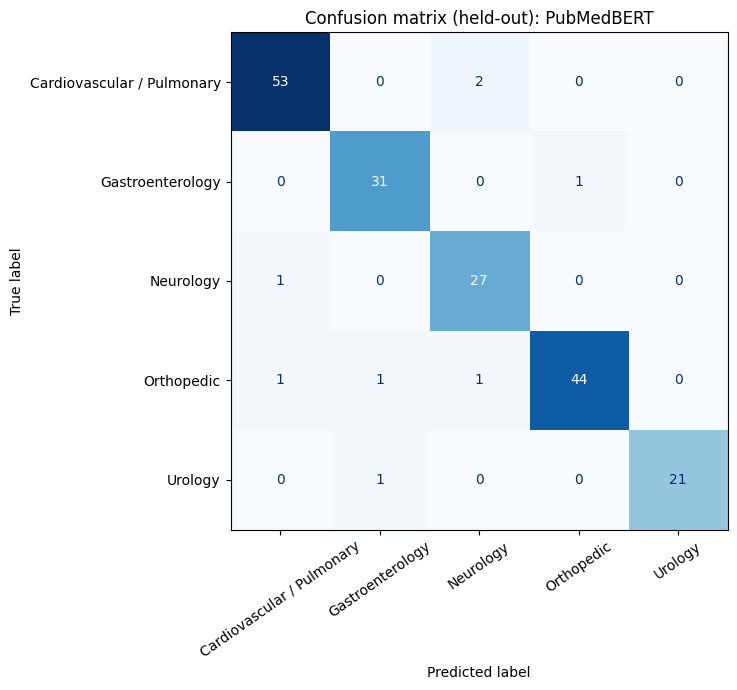

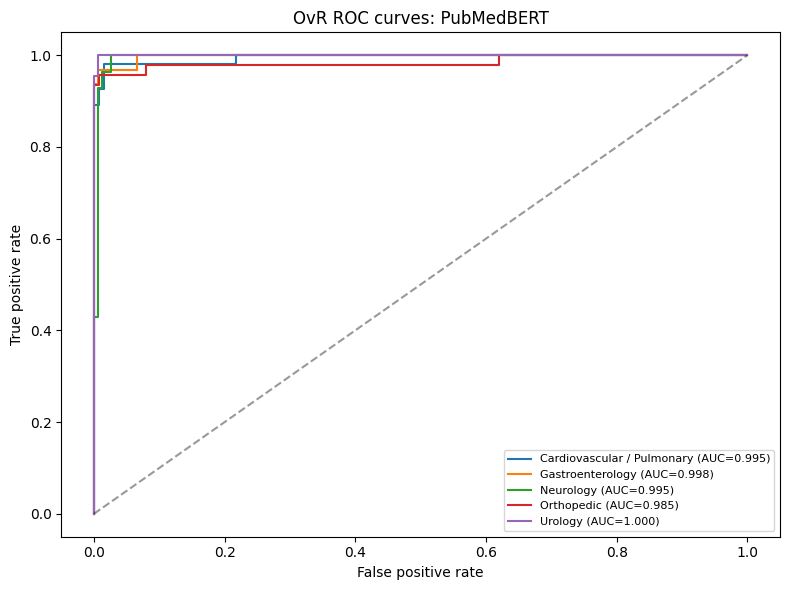

Misclassified cases saved without note content: 8


In [11]:
choice_probs=test_predictions[selected_name]
choice_preds=np.argmax(choice_probs,axis=1)
print(classification_report(test.y,choice_preds,target_names=class_names,zero_division=0))
cm=confusion_matrix(test.y,choice_preds,labels=np.arange(n_classes))
fig,ax=plt.subplots(figsize=(9,7))
ConfusionMatrixDisplay(cm,display_labels=class_names).plot(ax=ax,xticks_rotation=35,cmap='Blues',colorbar=False)
ax.set_title(f'Confusion matrix (held-out): {selected_name}')
fig.tight_layout();fig.savefig(OUT/'confusion_matrix.png',dpi=200);plt.show()

bin_y=label_binarize(test.y,classes=np.arange(n_classes))
fig,ax=plt.subplots(figsize=(8,6))
for k,label in enumerate(class_names):
    fpr,tpr,_=roc_curve(bin_y[:,k],choice_probs[:,k]); au=auc(fpr,tpr)
    ax.plot(fpr,tpr,label=f'{label} (AUC={au:.3f})')
ax.plot([0,1],[0,1],'k--',alpha=.4)
ax.set(xlabel='False positive rate',ylabel='True positive rate',title=f'OvR ROC curves: {selected_name}')
ax.legend(fontsize=8,loc='lower right');fig.tight_layout()
fig.savefig(OUT/'roc_curves.png',dpi=200);plt.show()

errors=pd.DataFrame({'record_id':test.signature.apply(lambda s:hashlib.sha256(s.encode()).hexdigest()[:14]),
                     'actual':enc.inverse_transform(test.y),
                     'predicted':enc.inverse_transform(choice_preds),
                     'confidence':np.max(choice_probs,axis=1)})
errors[errors.actual!=errors.predicted].to_csv(OUT/'misclassified_cases_no_text.csv',index=False)
print('Misclassified cases saved without note content:',int((errors.actual!=errors.predicted).sum()))

## 10. Robustness: label-preserving formatting stress, plus length-based shift audit

Formatting stress adds irregular whitespace and capitalization, which should not change the specialty label. This is an **internal robustness test, not a true external out-of-distribution test**. A true OOD assessment requires a separate representative corpus from another site or time period with compatible independently verified labels.

The length-stratified analysis is a **distribution-shift proxy**, not demographic fairness or external validation.

In [12]:
def format_perturb(s):
    s=s.swapcase()
    s=re.sub(r' +','   ',s)
    s=s.replace('. ','.\n')
    return s

perturbed=test.text.apply(format_perturb).tolist()
stress_rows=[]
for name in test_predictions:
    noisy=predict_any(name,perturbed)
    base=test_results[name]['f1_macro']
    stressed=evaluate_arrays(test.y,noisy)['f1_macro']
    stress_rows.append({'model':name,'original_macro_f1':base,'format_stress_macro_f1':stressed,
                        'macro_f1_change':stressed-base})
stress=pd.DataFrame(stress_rows).set_index('model')
stress.to_csv(OUT/'formatting_robustness.csv')
display(stress.round(4))

note_lengths=test.text.str.split().str.len()
length_bins=pd.qcut(note_lengths,q=3,labels=['short','medium','long'],duplicates='drop')
shift_rows=[]
for name,probs in test_predictions.items():
    for group in length_bins.dropna().unique():
        mask=(length_bins==group).to_numpy()
        shift_rows.append({'model':name,'length_group':str(group),'n':int(mask.sum()),
                           'macro_f1':f1_score(test.y[mask],np.argmax(probs[mask],axis=1),
                                              labels=np.arange(n_classes),average='macro',zero_division=0)})
shift=pd.DataFrame(shift_rows)
shift.to_csv(OUT/'internal_length_shift.csv',index=False)
display(shift.pivot(index='model',columns='length_group',values='macro_f1').round(4))

,original_macro_f1,format_stress_macro_f1,macro_f1_change
model,,,
Logistic Regression,0.9245,0.9245,0.0
Linear SVM,0.9323,0.9323,0.0
Random Forest,0.9055,0.9055,0.0
ClinicalBERT,0.9350,0.9350,0.0
PubMedBERT,0.9564,0.9564,0.0


length_group,long,medium,short
model,,,
ClinicalBERT,0.9316,0.9429,0.9255
Linear SVM,0.9109,0.9238,0.9453
Logistic Regression,0.9109,0.9212,0.9232
PubMedBERT,0.9721,0.9437,0.9450
Random Forest,0.9129,0.8977,0.8832


## 11. Significance: exact McNemar + paired bootstrap CI

Compare the validation-selected model against the next-best validation model using paired predictions on the same untouched test notes. McNemar tests *discordant correctness*; a paired bootstrap estimates the difference in macro F1. These address different questions. Correct for multiple comparisons when adding more model pairs.

In [13]:
if len(selection)>=2:
    runner_up=selection.index[1]
    a=np.argmax(test_predictions[selected_name],axis=1)==test.y.to_numpy()
    b=np.argmax(test_predictions[runner_up],axis=1)==test.y.to_numpy()
    n10=int(np.sum(a & ~b));n01=int(np.sum(~a & b))
    p_mc=1.0 if n10+n01==0 else float(binomtest(min(n10,n01),n10+n01,p=0.5,alternative='two-sided').pvalue)
    rng=np.random.default_rng(SEED)
    differences=[]
    y=test.y.to_numpy()
    pa=np.argmax(test_predictions[selected_name],axis=1)
    pb=np.argmax(test_predictions[runner_up],axis=1)
    for _ in range(2000):
        idx=rng.integers(0,len(y),len(y))
        differences.append(f1_score(y[idx],pa[idx],labels=np.arange(n_classes),average='macro',zero_division=0)
                         -f1_score(y[idx],pb[idx],labels=np.arange(n_classes),average='macro',zero_division=0))
    lo,hi=np.quantile(differences,[0.025,0.975])
    stats={'selected':selected_name,'comparator':runner_up,'n_selected_correct_only':n10,
           'n_comparator_correct_only':n01,'mcnemar_exact_p':p_mc,
           'test_macro_f1_difference':float(test_results[selected_name]['f1_macro']-
                                            test_results[runner_up]['f1_macro']),
           'bootstrap_ci_95_low':float(lo),'bootstrap_ci_95_high':float(hi)}
    pd.DataFrame([stats]).to_csv(OUT/'paired_significance.csv',index=False)
    print(pd.Series(stats))

selected                       PubMedBERT
comparator                   ClinicalBERT
n_selected_correct_only                 5
n_comparator_correct_only               2
mcnemar_exact_p                  0.453125
test_macro_f1_difference         0.021365
bootstrap_ci_95_low             -0.009418
bootstrap_ci_95_high             0.055429
dtype: object


## 12. Exploratory paired t-tests on repeat-CV baseline scores

Because repeated CV training sets overlap, ordinary paired t-test p-values are **exploratory, not independent-fold confirmatory evidence**. They compare **traditional baselines only**. For transformer-vs-transformer stability, repeat fine-tuning across fixed seeds or separate folds and report uncertainty. Three CV scores alone are not enough for a strong significance claim.

In [14]:
rskf=RepeatedStratifiedKFold(n_splits=3,n_repeats=2,random_state=SEED)
cv_scores={}
for name,estimator in fitted.items():
    scores=cross_val_score(estimator,train.text,train.y,cv=rskf,scoring='f1_macro',n_jobs=2)
    cv_scores[name]=scores
    print(name,'scores:',np.round(scores,4),'mean:',round(scores.mean(),4))
cv_table=pd.DataFrame(cv_scores);cv_table.to_csv(OUT/'repeated_cv_scores.csv',index=False)
comparison=[]
for a,b in itertools.combinations(cv_scores,2):
    t,p=ttest_rel(cv_scores[a],cv_scores[b])
    comparison.append({'model_a':a,'model_b':b,'t_stat':float(t),'p_raw':float(p),
                       'mean_fold_f1_difference':float(np.mean(cv_scores[a]-cv_scores[b]))})
if comparison:
    adjusted=multipletests([x['p_raw'] for x in comparison],method='holm')[1]
    for row,p in zip(comparison,adjusted):row['p_holm']=float(p)
    display(pd.DataFrame(comparison).round(4))
    pd.DataFrame(comparison).to_csv(OUT/'exploratory_paired_ttests.csv',index=False)

Logistic Regression scores: [0.9112 0.9224 0.9434 0.9323 0.898  0.9598] mean: 0.9279
Linear SVM scores: [0.9198 0.9645 0.9365 0.9399 0.9138 0.9756] mean: 0.9417
Random Forest scores: [0.8679 0.8621 0.8625 0.8178 0.8249 0.9052] mean: 0.8567


,model_a,model_b,t_stat,p_raw,mean_fold_f1_difference,p_holm
0,Logistic Regression,Linear SVM,-2.1006,0.0897,-0.0138,0.0897
1,Logistic Regression,Random Forest,6.9471,0.0009,0.0712,0.0019
2,Linear SVM,Random Forest,8.3246,0.0004,0.0850,0.0012


## 13. Interpretability: SHAP + LIME on an interpretable baseline

Use Logistic Regression because its TF-IDF features support direct token-level examination. **Explanations identify associations, not causal clinical evidence.** The baseline may not be the final model, but provides an interpretable reference. Attention weights are not automatically faithful explanations of model behavior.

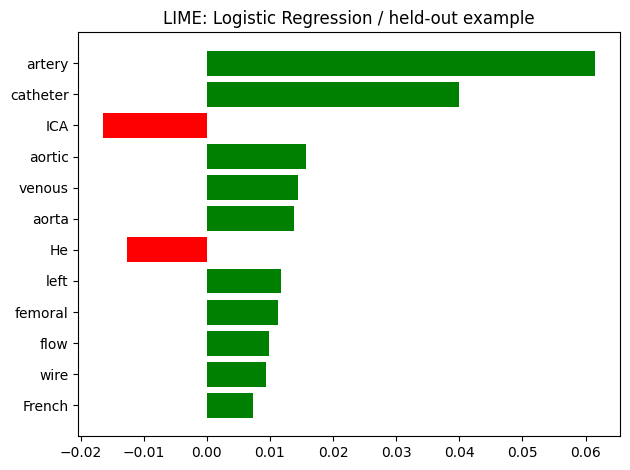

LIME token-weight list (inspect for shortcuts): [(np.str_('artery'), 0.06156429261386434), (np.str_('catheter'), 0.03999334036697247), (np.str_('ICA'), -0.016445622363158496), (np.str_('aortic'), 0.015763392948797167), (np.str_('venous'), 0.014518558167508513), (np.str_('aorta'), 0.013835969106759763), (np.str_('He'), -0.012615709561763543), (np.str_('left'), 0.011697707014306754), (np.str_('femoral'), 0.011327898891199359), (np.str_('flow'), 0.009789709356606481), (np.str_('wire'), 0.009387167898162262), (np.str_('French'), 0.007302757932372041)]


In [15]:
# LIME: model-agnostic local explanation of one *held-out* note.
from lime.lime_text import LimeTextExplainer
baseline=fitted['Logistic Regression']
example_idx=0
predict_proba_text=lambda texts:baseline.predict_proba(list(texts))
explainer_lime=LimeTextExplainer(class_names=class_names,random_state=SEED)
example_class=int(baseline.predict([test.text.iloc[example_idx]])[0])
lime_exp=explainer_lime.explain_instance(test.text.iloc[example_idx],predict_proba_text,
                                        num_features=12,labels=(example_class,),num_samples=500)
fig=lime_exp.as_pyplot_figure(label=example_class)
plt.title('LIME: Logistic Regression / held-out example')
plt.tight_layout();plt.savefig(OUT/'lime_local_explanation.png',dpi=180);plt.show()
print('LIME token-weight list (inspect for shortcuts):',lime_exp.as_list(label=example_class))

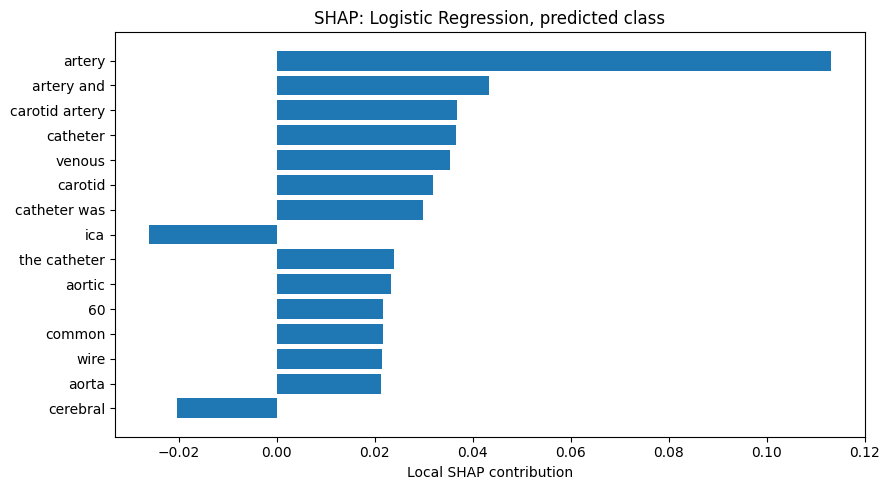

In [16]:
# SHAP: linear explanation on a sparse TF-IDF representation; may use extra RAM.
try:
    import shap
    X_bg=baseline.named_steps['tfidf'].transform(train.text.iloc[:100])
    X_one=baseline.named_steps['tfidf'].transform(test.text.iloc[:1])
    shap_explainer=shap.LinearExplainer(baseline.named_steps['clf'],X_bg)
    ev=shap_explainer(X_one)
    values=np.asarray(ev.values)
    target=example_class
    if values.ndim==3:imp=values[0,:,target]
    else:imp=values[0,:]
    features=np.asarray(baseline.named_steps['tfidf'].get_feature_names_out())
    top=np.argsort(np.abs(imp))[-15:]
    fig,ax=plt.subplots(figsize=(9,5))
    ax.barh(features[top],imp[top]);ax.set_title('SHAP: Logistic Regression, predicted class')
    ax.set_xlabel('Local SHAP contribution');fig.tight_layout()
    fig.savefig(OUT/'shap_local_explanation.png',dpi=180);plt.show()
except Exception as exc:
    print('SHAP could not run automatically in this environment:',type(exc).__name__,str(exc)[:250])
    print('Do not claim SHAP results unless this cell generates the plot successfully.')

## 14. Ethics/fairness audit and limitations

**Do not fabricate demographic-parity or equal-opportunity scores.** The source CSV has no verified protected-group columns suitable for those calculations. Equal opportunity also requires a clear positive outcome, which is not intrinsically defined for a five-way specialty classifier. An appropriate future fairness study needs lawful demographic labels, valid outcome definitions, sufficient group sizes, and clinical review.

Assess PHI handling manually, audit label quality and shortcut leakage, and obtain external multicenter validation before proposing any clinical decision support deployment.

In [17]:
audit=pd.DataFrame([
 {'criterion':'Verified diagnosis labels','status':'NOT AVAILABLE','consequence':'No diagnosis accuracy or clinical sensitivity claims'},
 {'criterion':'Protected-group demographic labels','status':'NOT AVAILABLE','consequence':'Demographic parity/equal opportunity not estimable'},
 {'criterion':'True out-of-distribution notes','status':'NOT INCLUDED','consequence':'Only formatting and length-based internal stress tests'},
 {'criterion':'Formal PHI de-identification','status':'NOT VALIDATED','consequence':'Screen and restrict note access; do not treat regex as compliance'},
 {'criterion':'Clinician validation','status':'NOT PERFORMED','consequence':'No independent clinical deployment recommendation'},
 {'criterion':'Held-out test','status':'EVALUATED','consequence':f'Validation-selected model: {selected_name}'}])
display(audit)
audit.to_csv(OUT/'ethical_audit.csv',index=False)

,criterion,status,consequence
0,Verified diagnosis labels,NOT AVAILABLE,No diagnosis accuracy or clinical sensitivity ...
1,Protected-group demographic labels,NOT AVAILABLE,Demographic parity/equal opportunity not estim...
2,True out-of-distribution notes,NOT INCLUDED,Only formatting and length-based internal stre...
3,Formal PHI de-identification,NOT VALIDATED,Screen and restrict note access; do not treat ...
4,Clinician validation,NOT PERFORMED,No independent clinical deployment recommendation
5,Held-out test,EVALUATED,Validation-selected model: PubMedBERT


## 15. Export results for the companion technical report

Use the produced numeric results and image files to replace the placeholders in the technical-report document. Keep a copy of this notebook with output cells for reproducibility. **Never write a performance claim until the relevant cell executes successfully.**

In [18]:
summary={'n_original_rows':int(len(raw)), 'n_final_rows':len(df),'split_counts':{'train':len(train),'val':len(val),'test':len(test)},
         'class_names':class_names,'validation_selected':selected_name,
         'validation_metrics':val_records,'test_metrics':test_results,
         'model_metadata':model_metadata}
with open(OUT/'study_summary.json','w') as f:json.dump(summary,f,indent=2,default=float)
print('Files generated:')
for p in sorted(OUT.iterdir()):
    print(' ',p.name)
import shutil
archive=shutil.make_archive(str(OUT),'zip',root_dir=str(OUT))
print('Results ZIP:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

Files generated:
  checkpoints
  class_distribution.png
  cohort_audit.json
  confusion_matrix.png
  ethical_audit.csv
  exploratory_paired_ttests.csv
  formatting_robustness.csv
  internal_length_shift.csv
  lime_local_explanation.png
  linear_svm.joblib
  logistic_regression.joblib
  misclassified_cases_no_text.csv
  mlflow.db
  models
  paired_significance.csv
  random_forest.joblib
  repeated_cv_scores.csv
  roc_curves.png
  shap_local_explanation.png
  study_summary.json
  test_model_comparison.csv
  test_split_manifest.csv
  train_split_manifest.csv
  validation_scores.csv
  validation_split_manifest.csv
Results ZIP: /content/medical_model_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## References and suggested citations (APA)

- Boyle, T. (n.d.). *Medical Transcriptions* [Data set]. Kaggle. https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions
- Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (2nd ed.). O'Reilly Media.
- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0
- Alsentzer, E., Murphy, J. R., Boag, W., Weng, W.-H., Jin, D., Naumann, T., & McDermott, M. B. A. (2019). Publicly available clinical BERT embeddings. *Proceedings of the 2nd Clinical Natural Language Processing Workshop*, 72–78. https://aclanthology.org/W19-1909/
- Gu, Y., Tinn, R., Cheng, H., Lucas, M., Usuyama, N., Liu, X., Naumann, T., Gao, J., & Poon, H. (2022). Domain-specific language model pretraining for biomedical natural language processing. *ACM Transactions on Computing for Healthcare, 3*(1), 1–23. https://doi.org/10.1145/3458754

Actual performance figures, plots, bootstrap confidence intervals, and significance tests must be produced by the notebook; none are assumed in advance.